In [2]:
# Load the required packages
%matplotlib inline

# scitnific computing and plotting
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

# HDDM related packages
import pymc as pm
import hddm
import kabuki
import arviz as az
print("The current HDDM version is: ", hddm.__version__)
print("The current kabuki version is: ", kabuki.__version__)
print("The current PyMC version is: ", pm.__version__)
print("The current ArviZ version is: ", az.__version__)

import warnings
warnings.filterwarnings('ignore') 

The current HDDM version is:  1.0.1RC
The current kabuki version is:  0.6.5RC4
The current PyMC version is:  2.3.8
The current ArviZ version is:  1.1.0


## Import models

In [ ]:
id_vz = hddm.load('m_id_vz.hddm')
irrshape_v = hddm.load('m_irrshape_v.hddm')
irrcolor_v = hddm.load('m_irrcolor_v.hddm')

## Identity task and identity-relevant task

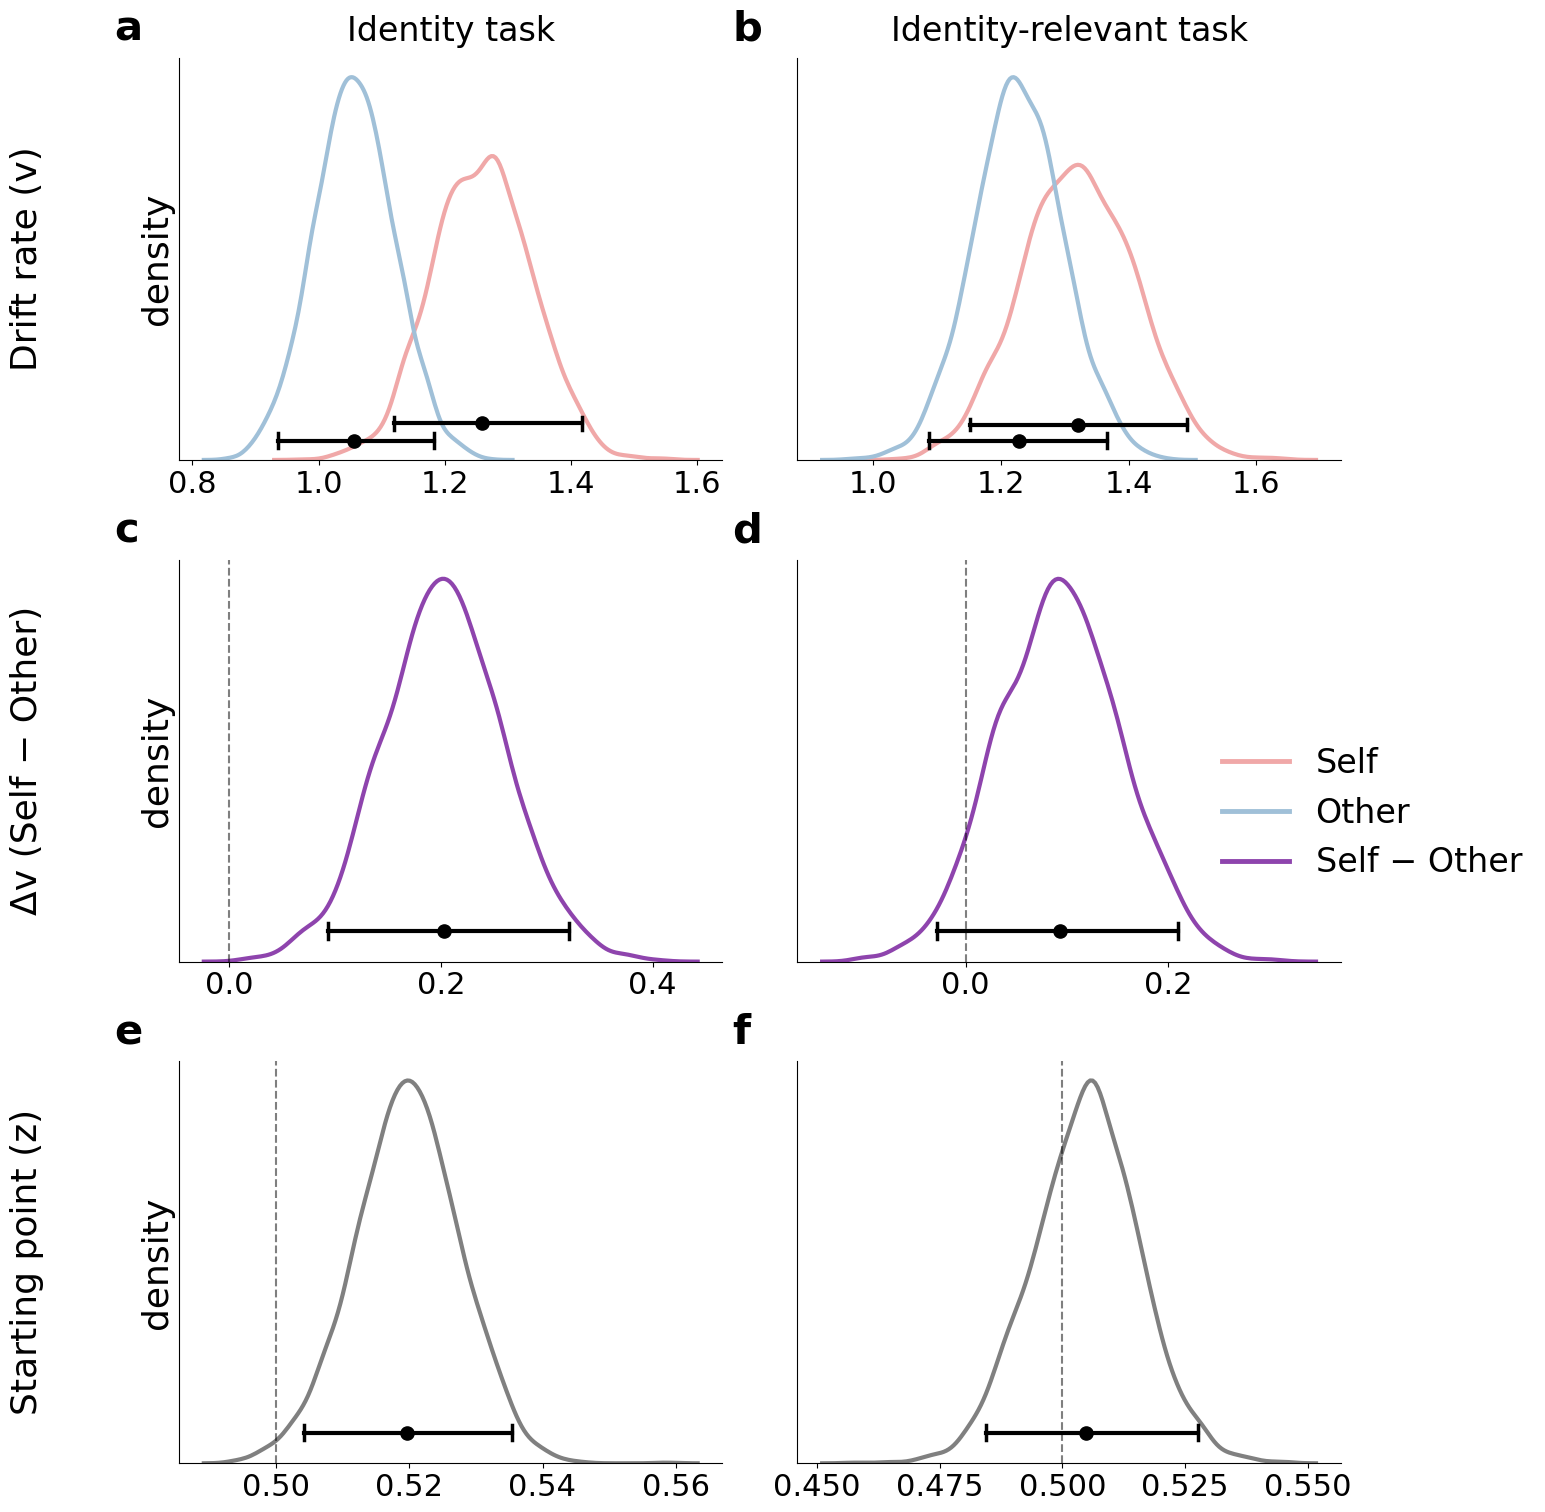

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D

# ========================== Extract posterior samples ==========================
samples = m2_vz.posterior_trace_df

# ---- Coefficients for v ----
v_Intercept        = samples['v_Intercept']
v_association_self = samples['v_association[T.self]']
v_task_relevant    = samples['v_task_type[T.relevant]']
v_assoc_task       = samples['v_task_type[T.relevant]:association[T.self]']

# ---- Coefficients for z (logit space) ----
z_Intercept        = samples['z_Intercept']
z_task_relevant    = samples['z_task_type[T.relevant]']


# ========================== HDI function ==========================
def hdi(samples, prob=0.95):
    sorted_samples = np.sort(samples)
    n = len(sorted_samples)
    gap = int(n * prob)
    width = sorted_samples[gap:] - sorted_samples[:n - gap]
    idx = np.argmin(width)
    return sorted_samples[idx], sorted_samples[idx + gap]


# ========================== Compute parameter values under different conditions ==========================
def compute_condition(param, relevant_cond, assoc_cond):
    if param == 'v':
        Intercept     = v_Intercept
        assoc_self    = v_association_self
        task_relevant = v_task_relevant
        assoc_task    = v_assoc_task

        if relevant_cond == 'overlap':
            if assoc_cond == 'Other':
                val = Intercept
            else:
                val = Intercept + assoc_self
        else:  # relevant
            if assoc_cond == 'Other':
                val = Intercept + task_relevant
            else:
                val = Intercept + task_relevant + assoc_self + assoc_task

        return val.values

    else:  # z: only distinguished by task_type, not by association
        if relevant_cond == 'overlap':
            z_logit = z_Intercept
        else:
            z_logit = z_Intercept + z_task_relevant

        return z_logit.values


conditions = []

# v: 4 conditions
for relevant_cond in ['overlap', 'relevant']:
    for assoc_cond in ['Other', 'Self']:
        val = compute_condition('v', relevant_cond, assoc_cond)
        conditions.append({
            'param':       'v',
            'relevant':    relevant_cond,
            'association': assoc_cond,
            'samples':     val
        })

# v difference: Self - Other (subtracted sample by sample)
for relevant_cond in ['overlap', 'relevant']:
    s_self  = compute_condition('v', relevant_cond, 'Self')
    s_other = compute_condition('v', relevant_cond, 'Other')
    conditions.append({
        'param':       'dv',
        'relevant':    relevant_cond,
        'association': None,
        'samples':     (s_self - s_other)
    })

# z: 2 conditions
for relevant_cond in ['overlap', 'relevant']:
    val = compute_condition('z', relevant_cond, None)
    conditions.append({
        'param':       'z',
        'relevant':    relevant_cond,
        'association': None,
        'samples':     val
    })


# ========================== Plotting function ==========================
def plot_posterior(ax, data, color, is_self):
    linestyle = "-" if is_self else "-"

    kde_plot = sns.kdeplot(data, color=color, linewidth=3,
                           linestyle=linestyle, ax=ax)
    kde_line = kde_plot.lines[-1]
    y_max = kde_line.get_ydata().max()

    y_hdi = y_max * 0.12 if is_self else y_max * 0.05

    mean_val = np.mean(data)
    h_low, h_high = hdi(data)

    ax.scatter(mean_val, y_hdi, color="black", s=90, zorder=5)
    ax.plot([h_low, h_high], [y_hdi, y_hdi], color="black", linewidth=3, zorder=4)
    ax.plot([h_low, h_low],  [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
            color="black", linewidth=2.5, zorder=4)
    ax.plot([h_high, h_high], [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
            color="black", linewidth=2.5, zorder=4)


# ========================== Plotting ==========================
color_self  = "#F0A8A8"
color_other = "#A0C0D8"
color_z     = "gray"
color_dv    = "#8E44AD"

FS_LABEL    = 30
FS_TICK     = 22
FS_TITLE    = 24
FS_ROWTITLE = 26
FS_LEGEND   = 24
FS_YLABEL   = 26
FS_PANEL    = 30    # ★ panel label font size

fig, axes = plt.subplots(3, 2, figsize=(14, 16), sharex=False, sharey=False, dpi=100)

row_params = ['v', 'dv', 'z']
col_tasks  = ['overlap', 'relevant']
row_labels = {'v':  'Drift rate (v)',
              'dv': 'Δv (Self − Other)',
              'z':  'Starting point (z)'}
col_labels = {'overlap':  'Identity task',
              'relevant': 'Identity-relevant task'}

# ★ panel label mapping: (row, col) -> letter
panel_labels = {
    (0, 0): 'a', (0, 1): 'b',
    (1, 0): 'c', (1, 1): 'd',
    (2, 0): 'e', (2, 1): 'f',
}

plt.subplots_adjust(hspace=0.55, wspace=0.25)

for row_idx, param in enumerate(row_params):
    for col_idx, task in enumerate(col_tasks):
        ax = axes[row_idx, col_idx]

        conds = [c for c in conditions
                 if c['param'] == param and c['relevant'] == task]

        # ---------------- KDE + HDI ----------------
        if param == 'z':
            data = conds[0]['samples']
            kde_plot = sns.kdeplot(data, color=color_z, linewidth=3,
                                   linestyle='-', ax=ax)
            kde_line = kde_plot.lines[-1]
            y_max = kde_line.get_ydata().max()

            y_hdi = y_max * 0.08
            mean_val = np.mean(data)
            h_low, h_high = hdi(data)

            ax.scatter(mean_val, y_hdi, color="black", s=90, zorder=5)
            ax.plot([h_low, h_high], [y_hdi, y_hdi],
                    color="black", linewidth=3, zorder=4)
            ax.plot([h_low, h_low],  [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
                    color="black", linewidth=2.5, zorder=4)
            ax.plot([h_high, h_high], [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
                    color="black", linewidth=2.5, zorder=4)

        elif param == 'dv':
            data = conds[0]['samples']
            kde_plot = sns.kdeplot(data, color=color_dv, linewidth=3,
                                   linestyle='-', ax=ax)
            kde_line = kde_plot.lines[-1]
            y_max = kde_line.get_ydata().max()

            y_hdi = y_max * 0.08
            mean_val = np.mean(data)
            h_low, h_high = hdi(data)

            ax.scatter(mean_val, y_hdi, color="black", s=90, zorder=5)
            ax.plot([h_low, h_high], [y_hdi, y_hdi],
                    color="black", linewidth=3, zorder=4)
            ax.plot([h_low, h_low],  [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
                    color="black", linewidth=2.5, zorder=4)
            ax.plot([h_high, h_high], [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
                    color="black", linewidth=2.5, zorder=4)

        else:  # v
            data_self  = [c for c in conds if c['association'] == 'Self'][0]['samples']
            data_other = [c for c in conds if c['association'] == 'Other'][0]['samples']
            plot_posterior(ax, data_self,  color_self,  is_self=True)
            plot_posterior(ax, data_other, color_other, is_self=False)

        # ---------------- ★ panel label ----------------
        ax.text(-0.12, 1.02, panel_labels[(row_idx, col_idx)],
                transform=ax.transAxes,
                fontsize=FS_PANEL, fontweight='bold',
                ha='left', va='bottom')

        # ---------------- Axes and titles ----------------
        ax.tick_params(axis='x', labelsize=FS_TICK)

        if col_idx == 0:
            ax.set_ylabel('density', fontsize=FS_YLABEL)
            ax.set_yticks([])
            ax.tick_params(axis='y', labelsize=FS_TICK)
        else:
            ax.set_ylabel('')
            ax.set_yticks([])
            ax.tick_params(axis='y', left=False, labelleft=False)

        # Reference lines: none for v in the first row; 0 for dv; 0.5 for z
        if param == 'z':
            ax.axvline(0.5, linestyle="--", c="black", alpha=0.5, linewidth=1.5)
        elif param == 'dv':
            ax.axvline(0, linestyle="--", c="black", alpha=0.5, linewidth=1.5)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(False)

        if row_idx == 0:
            ax.set_title(col_labels[task], fontsize=FS_TITLE, pad=12)

# ---- Row titles on the left of each row ----
for row_idx, param in enumerate(row_params):
    axes[row_idx, 0].text(-0.28, 0.5, row_labels[param],
                          fontsize=FS_ROWTITLE, ha='center', va='center',
                          rotation=90, transform=axes[row_idx, 0].transAxes)

# ---- Legend ----
legend_elements = [
    Line2D([0], [0], color=color_self,  lw=3.5, linestyle='-', label='Self'),
    Line2D([0], [0], color=color_other, lw=3.5, linestyle='-', label='Other'),
    Line2D([0], [0], color=color_dv,    lw=3.5, linestyle='-', label='Self − Other'),
]
fig.legend(handles=legend_elements, loc='upper right',
           bbox_to_anchor=(1.10, 0.5), fontsize=FS_LEGEND, frameon=False)

plt.tight_layout(rect=[0, 0, 0.97, 0.95])
plt.savefig('Fig/rdk_v_z_final.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
# ========================== Output mean + 95% HDI ==========================
print("======================")

# ---- v: irrelevant ----
v_irr_self  = [c for c in conditions if c['param']=='v' and c['relevant']=='irrelevant' and c['association']=='Self'][0]['samples']
v_irr_other = [c for c in conditions if c['param']=='v' and c['relevant']=='irrelevant' and c['association']=='Other'][0]['samples']

v_irr_self_mean  = np.mean(v_irr_self)
v_irr_other_mean = np.mean(v_irr_other)
v_irr_self_low,  v_irr_self_high  = hdi(v_irr_self)
v_irr_other_low, v_irr_other_high = hdi(v_irr_other)

print(f"v(irrelevant, Self )  均值 = {v_irr_self_mean:.3f}  |  95% HDI = [{v_irr_self_low:.3f}, {v_irr_self_high:.3f}]")
print(f"v(irrelevant, Other)  均值 = {v_irr_other_mean:.3f}  |  95% HDI = [{v_irr_other_low:.3f}, {v_irr_other_high:.3f}]")

# ---- v: relevant ----
v_rel_self  = [c for c in conditions if c['param']=='v' and c['relevant']=='relevant' and c['association']=='Self'][0]['samples']
v_rel_other = [c for c in conditions if c['param']=='v' and c['relevant']=='relevant' and c['association']=='Other'][0]['samples']

v_rel_self_mean  = np.mean(v_rel_self)
v_rel_other_mean = np.mean(v_rel_other)
v_rel_self_low,  v_rel_self_high  = hdi(v_rel_self)
v_rel_other_low, v_rel_other_high = hdi(v_rel_other)

print(f"v(relevant,   Self )  均值 = {v_rel_self_mean:.3f}  |  95% HDI = [{v_rel_self_low:.3f}, {v_rel_self_high:.3f}]")
print(f"v(relevant,   Other)  均值 = {v_rel_other_mean:.3f}  |  95% HDI = [{v_rel_other_low:.3f}, {v_rel_other_high:.3f}]")

print("----------------------")

# ---- z: irrelevant ----
z_irr = [c for c in conditions if c['param']=='z' and c['relevant']=='irrelevant'][0]['samples']
z_irr_mean = np.mean(z_irr)
z_irr_low, z_irr_high = hdi(z_irr)

print(f"z(irrelevant)  均值 = {z_irr_mean:.3f}  |  95% HDI = [{z_irr_low:.3f}, {z_irr_high:.3f}]")

# ---- z: relevant ----
z_rel = [c for c in conditions if c['param']=='z' and c['relevant']=='relevant'][0]['samples']
z_rel_mean = np.mean(z_rel)
z_rel_low, z_rel_high = hdi(z_rel)

print(f"z(relevant)    均值 = {z_rel_mean:.3f}  |  95% HDI = [{z_rel_low:.3f}, {z_rel_high:.3f}]")

print("======================")

v(irrelevant, Self )  均值 = 1.261  |  95% HDI = [1.106, 1.422]
v(irrelevant, Other)  均值 = 1.055  |  95% HDI = [0.927, 1.184]
v(relevant,   Self )  均值 = 1.321  |  95% HDI = [1.149, 1.489]
v(relevant,   Other)  均值 = 1.232  |  95% HDI = [1.095, 1.379]
----------------------
z(irrelevant)  均值 = 0.519  |  95% HDI = [0.503, 0.535]
z(relevant)    均值 = 0.505  |  95% HDI = [0.484, 0.527]


In [ ]:
# ========================== Extract posterior samples for each condition ==========================
v_irr_self  = [c for c in conditions if c['param']=='v' and c['relevant']=='irrelevant' and c['association']=='Self'][0]['samples']
v_irr_other = [c for c in conditions if c['param']=='v' and c['relevant']=='irrelevant' and c['association']=='Other'][0]['samples']
v_rel_self  = [c for c in conditions if c['param']=='v' and c['relevant']=='relevant'   and c['association']=='Self'][0]['samples']
v_rel_other = [c for c in conditions if c['param']=='v' and c['relevant']=='relevant'   and c['association']=='Other'][0]['samples']

z_irr = [c for c in conditions if c['param']=='z' and c['relevant']=='irrelevant'][0]['samples']
z_rel = [c for c in conditions if c['param']=='z' and c['relevant']=='relevant'][0]['samples']


# ========================== Aggregate v by task (average across Self/Other) ==========================
v_irr = (v_irr_self + v_irr_other) / 2    
v_rel = (v_rel_self + v_rel_other) / 2

# ========================== Aggregate v by association (average across tasks) ==========================
v_self  = (v_irr_self + v_rel_self) / 2
v_other = (v_irr_other + v_rel_other) / 2


# ========================== Output mean + 95% HDI ==========================
print("======================")

# ---- v by task ----
v_irr_mean = np.mean(v_irr)
v_irr_low, v_irr_high = hdi(v_irr)
print(f"v(irrelevant)  均值 = {v_irr_mean:.3f}  |  95% HDI = [{v_irr_low:.3f}, {v_irr_high:.3f}]")

v_rel_mean = np.mean(v_rel)
v_rel_low, v_rel_high = hdi(v_rel)
print(f"v(relevant)    均值 = {v_rel_mean:.3f}  |  95% HDI = [{v_rel_low:.3f}, {v_rel_high:.3f}]")

print("----------------------")

# ---- v by association ----
v_self_mean = np.mean(v_self)
v_self_low, v_self_high = hdi(v_self)
print(f"v(Self)   均值 = {v_self_mean:.3f}  |  95% HDI = [{v_self_low:.3f}, {v_self_high:.3f}]")

v_other_mean = np.mean(v_other)
v_other_low, v_other_high = hdi(v_other)
print(f"v(Other)  均值 = {v_other_mean:.3f}  |  95% HDI = [{v_other_low:.3f}, {v_other_high:.3f}]")

print("----------------------")

# ---- z ----
z_irr_mean = np.mean(z_irr)
z_irr_low, z_irr_high = hdi(z_irr)
print(f"z(irrelevant)  均值 = {z_irr_mean:.3f}  |  95% HDI = [{z_irr_low:.3f}, {z_irr_high:.3f}]")

z_rel_mean = np.mean(z_rel)
z_rel_low, z_rel_high = hdi(z_rel)
print(f"z(relevant)    均值 = {z_rel_mean:.3f}  |  95% HDI = [{z_rel_low:.3f}, {z_rel_high:.3f}]")

print("======================")

v(irrelevant)  均值 = 1.158  |  95% HDI = [1.031, 1.297]
v(relevant)    均值 = 1.276  |  95% HDI = [1.133, 1.425]
----------------------
v(Self)   均值 = 1.291  |  95% HDI = [1.137, 1.452]
v(Other)  均值 = 1.143  |  95% HDI = [1.017, 1.273]
----------------------
z(irrelevant)  均值 = 0.519  |  95% HDI = [0.503, 0.535]
z(relevant)    均值 = 0.505  |  95% HDI = [0.484, 0.527]


## Identity-irrelevant task

[shape] Δv (Self − Other)
    均值 = -0.003   SD = 0.040   95% HDI = [-0.076, +0.078]
[color] Δv (Self − Other)
    均值 = +0.034   SD = 0.052   95% HDI = [-0.067, +0.136]


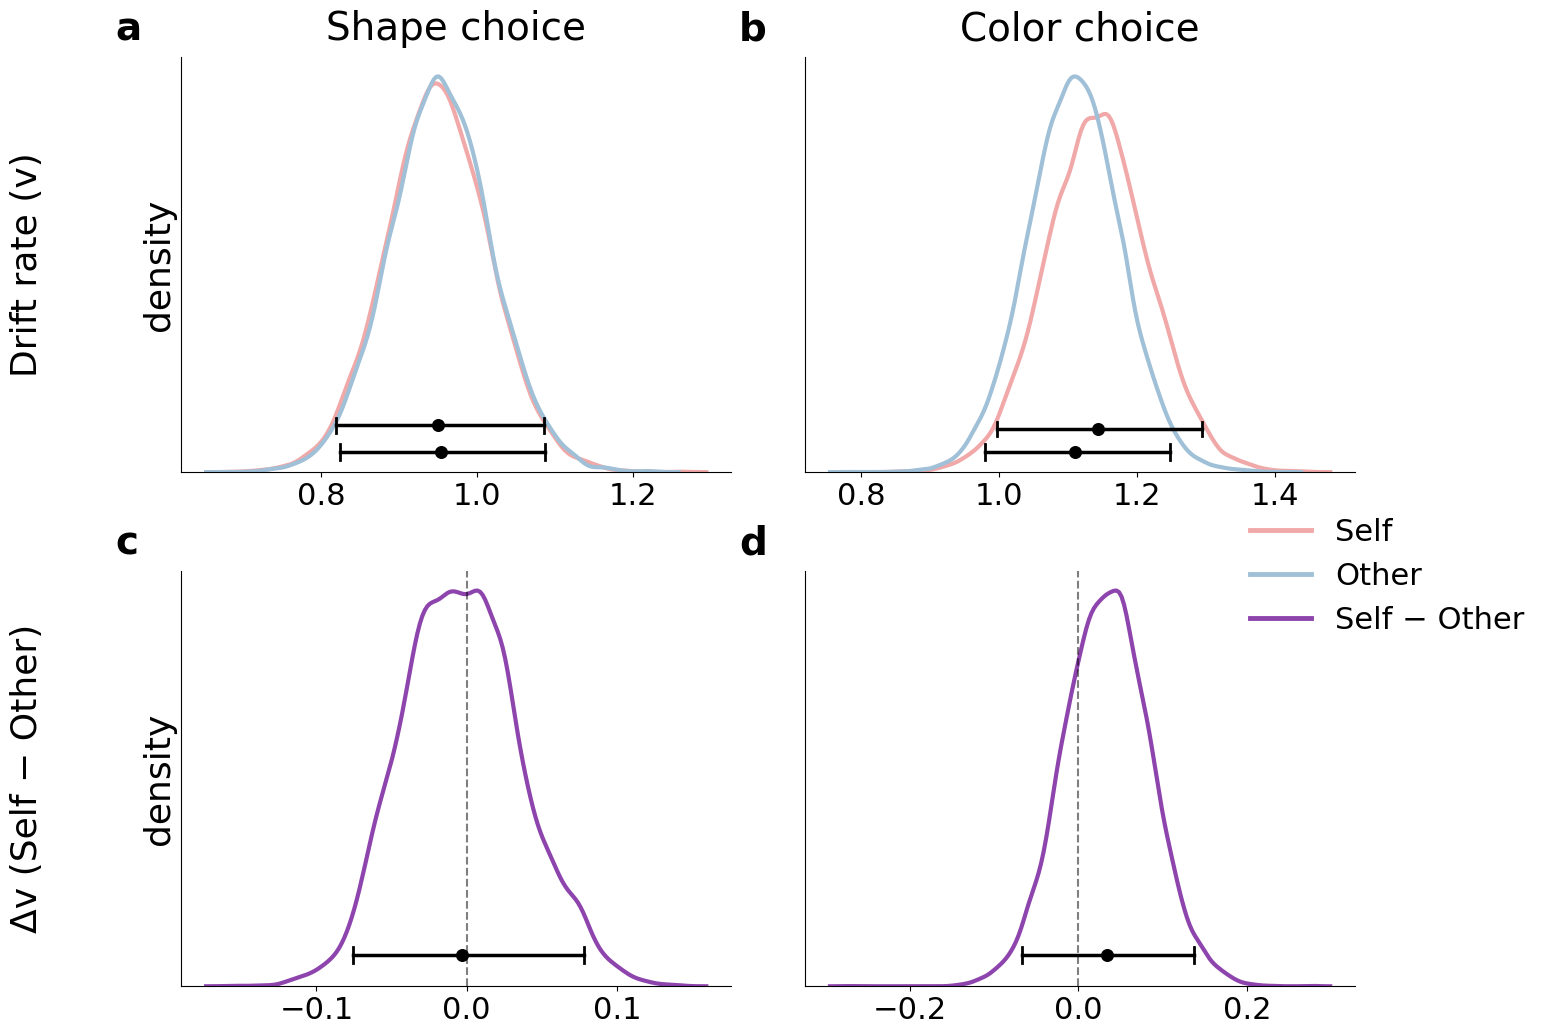

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.lines import Line2D

# ========================== Extract posterior samples from the two models ==========================
# ---- Model 1: shape (left column) ----
s_shape = irrshape_v.posterior_trace_df
v_Intercept_shape        = s_shape['v_Intercept']
v_association_self_shape = s_shape['v_association[T.self]']

# ---- Model 2: color (right column) ----
s_color = irrcolor_v.posterior_trace_df
v_Intercept_color        = s_color['v_Intercept']
v_association_self_color = s_color['v_association[T.self]']


# ========================== HDI function ==========================
def hdi(samples, prob=0.95):
    sorted_samples = np.sort(samples)
    n = len(sorted_samples)
    gap = int(n * prob)
    width = sorted_samples[gap:] - sorted_samples[:n - gap]
    idx = np.argmin(width)
    return sorted_samples[idx], sorted_samples[idx + gap]


# ========================== Assemble posterior samples of the two models ==========================
def build_conditions(v_Intercept, v_assoc_self):
    conds = []
    conds.append({'param': 'v',  'association': 'Other', 'samples': v_Intercept.values})
    conds.append({'param': 'v',  'association': 'Self',  'samples': (v_Intercept + v_assoc_self).values})
    conds.append({'param': 'dv', 'association': None,    'samples': v_assoc_self.values})  # difference = Self - Other
    return conds

conditions_shape = build_conditions(v_Intercept_shape, v_association_self_shape)
conditions_color = build_conditions(v_Intercept_color, v_association_self_color)


# ========================== ★ Print detailed results of the v difference ==========================
print("=" * 70)
for model_name, conds in [("shape", conditions_shape), ("color", conditions_color)]:
    dv_samples = [c for c in conds if c['param'] == 'dv'][0]['samples']
    mean_dv = np.mean(dv_samples)
    sd_dv   = np.std(dv_samples)
    lo_dv, hi_dv = hdi(dv_samples)
    print(f"[{model_name}] Δv (Self − Other)")
    print(f"    均值 = {mean_dv:+.3f}   SD = {sd_dv:.3f}   95% HDI = [{lo_dv:+.3f}, {hi_dv:+.3f}]")
print("=" * 70)


# ========================== Plotting function ==========================
def plot_posterior(ax, data, color, linestyle, y_hdi_frac):
    kde_plot = sns.kdeplot(data, color=color, linewidth=3,
                           linestyle=linestyle, ax=ax)
    kde_line = kde_plot.lines[-1]
    y_max = kde_line.get_ydata().max()

    y_hdi = y_max * y_hdi_frac

    mean_val = np.mean(data)
    h_low, h_high = hdi(data)

    ax.scatter(mean_val, y_hdi, color="black", s=70, zorder=5)
    ax.plot([h_low, h_high], [y_hdi, y_hdi], color="black", linewidth=2.5, zorder=4)
    ax.plot([h_low, h_low],  [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
            color="black", linewidth=2, zorder=4)
    ax.plot([h_high, h_high], [y_hdi - 0.02 * y_max, y_hdi + 0.02 * y_max],
            color="black", linewidth=2, zorder=4)


# ========================== Colors and fonts ==========================
color_self  = "#F0A8A8"
color_other = "#A0C0D8"
color_dv    = "#8E44AD"   # purple for the difference curve

FS_TICK     = 22
FS_TITLE    = 26
FS_ROWTITLE = 26
FS_COLTITLE = 28
FS_LEGEND   = 22
FS_YLABEL   = 26
FS_PANEL    = 28


# ========================== Plotting: 2×2 ==========================
fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=False, sharey=False, dpi=100)

row_params = ['v', 'dv']
col_models = ['shape', 'color']
row_labels = {'v': 'Drift rate (v)', 'dv': 'Δv (Self − Other)'}
col_labels = {'shape': 'Shape choice', 'color': 'Color choice'}

panel_labels = {
    (0, 0): 'a', (0, 1): 'b',
    (1, 0): 'c', (1, 1): 'd',
}

plt.subplots_adjust(hspace=0.45, wspace=0.22)

for row_idx, param in enumerate(row_params):
    for col_idx, model in enumerate(col_models):
        ax = axes[row_idx, col_idx]

        conds = conditions_shape if model == 'shape' else conditions_color

        if param == 'v':
            data_self  = [c for c in conds if c['param']=='v' and c['association']=='Self'][0]['samples']
            data_other = [c for c in conds if c['param']=='v' and c['association']=='Other'][0]['samples']
            plot_posterior(ax, data_self,  color_self,  '-', 0.12)
            plot_posterior(ax, data_other, color_other, '-', 0.05)

        else:  # param == 'dv'
            data_dv = [c for c in conds if c['param']=='dv'][0]['samples']
            plot_posterior(ax, data_dv, color_dv, '-', 0.08)

        # panel label
        ax.text(-0.12, 1.02, panel_labels[(row_idx, col_idx)],
                transform=ax.transAxes,
                fontsize=FS_PANEL, fontweight='bold',
                ha='left', va='bottom')

        # Axes
        ax.tick_params(axis='x', labelsize=FS_TICK)

        if col_idx == 0:
            ax.set_ylabel('density', fontsize=FS_YLABEL)
        else:
            ax.set_ylabel('')

        ax.set_yticks([])
        ax.tick_params(axis='y', left=False, labelleft=False)

        if param == 'dv':
            ax.axvline(0, linestyle="--", c="black", alpha=0.5, linewidth=1.5)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(False)

        if row_idx == 0:
            ax.set_title(col_labels[model], fontsize=FS_COLTITLE, pad=12)

# ---- Row titles on the left of each row ----
for row_idx, param in enumerate(row_params):
    axes[row_idx, 0].text(-0.28, 0.5, row_labels[param],
                          fontsize=FS_ROWTITLE, ha='center', va='center',
                          rotation=90, transform=axes[row_idx, 0].transAxes)

# ---- Legend ----
legend_elements = [
    Line2D([0], [0], color=color_self,  lw=3.5, linestyle='-', label='Self'),
    Line2D([0], [0], color=color_other, lw=3.5, linestyle='-', label='Other'),
    Line2D([0], [0], color=color_dv,    lw=3.5, linestyle='-', label='Self − Other'),
]
fig.legend(handles=legend_elements, loc='upper right',
           bbox_to_anchor=(1.10, 0.5), fontsize=FS_LEGEND, frameon=False)

plt.tight_layout(rect=[0, 0, 0.97, 0.95])
plt.savefig('Fig/rdk_v_z_two_models.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()